# Ray of Hope: ansiedad y depresión en el mundo

Este proyecto analiza la evolución de las tasas de ansiedad y depresión en diez países seleccionados durante el período 2014–2023, utilizando datos de salud mental del IHME (Global Burden of Disease 2023) e indicadores económicos del Banco Mundial.

El objetivo es explorar las diferencias entre los países, observar cómo evolucionaron los indicadores de salud mental durante la década y analizar su posible relación con el PIB per cápita.

Pregunta principal:

¿Cómo evolucionaron las tasas estimadas de ansiedad y depresión entre 2014 y 2023 en los diez países seleccionados por su mayor promedio anual de casos absolutos combinados, y qué relación presentan con el PIB per cápita?

Fuentes de datos:

IHME – Global Burden of Disease 2023: datos de prevalencia, número de casos y tasas de ansiedad y depresión.

Banco Mundial – World Bank API: indicadores económicos y demográficos, incluyendo PIB per cápita, tasa de desempleo y población.

Metodología general:

Primero, limpiamos y transformamos los datos del IHME, estandarizando los nombres de los países y asignando códigos ISO3. Después, seleccionamos los diez países con el mayor promedio anual de casos absolutos combinados de ansiedad y depresión entre 2014 y 2023.

A continuación, recopilamos los indicadores del Banco Mundial y combinamos ambas fuentes utilizando los códigos ISO3 y el año como claves de integración.

Finalmente, realizamos un análisis exploratorio para estudiar la evolución de las tasas de ansiedad y depresión y explorar su relación con el PIB per cápita.

## 2. Preparación

En esta sección configuramos el entorno de trabajo, verificamos la ubicación de los archivos del proyecto e importamos las funciones necesarias del módulo ray_of_hope_data.py.
Instalamos las dependencias requeridas para el procesamiento de los datos y ejecutamos las funciones de limpieza del archivo original del IHME.
Para consultar los indicadores del Banco Mundial, también necesitaremos conexión a internet.

In [239]:
%pip install pycountry Babel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [240]:
# Preparar archivos y rutas del proyecto

from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

# Directorio principal
PROJECT_ROOT = Path.cwd()

# Archivos del proyecto
PYTHON_FILE = PROJECT_ROOT / "ray_of_hope_data.py"

GBD_CSV = (
    PROJECT_ROOT
    / "IHME-GBD_2023_DATA-4c6692cd-1"
    / "IHME-GBD_2023_DATA-4c6692cd-1.csv"
)

# Verificar archivos
if not PYTHON_FILE.exists():
    raise FileNotFoundError("No se encontró ray_of_hope_data.py")

if not GBD_CSV.exists():
    raise FileNotFoundError(f"No se encontró el CSV: {GBD_CSV}")

# Importar funciones del proyecto
sys.path.insert(0, str(PROJECT_ROOT))

from ray_of_hope_data import (
    START_YEAR,
    END_YEAR,
    MIN_YEARS_FOR_RANKING,
    limpiar_ihme,
    rank_top10,
    build_dataframes
)

print("¡Proyecto configurado correctamente!")
print(f"Periodo: {START_YEAR}-{END_YEAR}")
print(f"Archivo IHME: {GBD_CSV.name}")

¡Proyecto configurado correctamente!
Periodo: 2014-2023
Archivo IHME: IHME-GBD_2023_DATA-4c6692cd-1.csv


In [241]:
# Limpiar y preparar los datos del IHME

df_mental, localidades_sin_iso3 = limpiar_ihme(GBD_CSV)

print("Registros preparados:", len(df_mental))
print("Países/localidades identificados:", df_mental["iso3"].nunique())
print("Localidades sin código ISO3:", len(localidades_sin_iso3))

display(df_mental.head(10))

Registros preparados: 2040
Países/localidades identificados: 204
Localidades sin código ISO3: 0


,country,iso3,year,anxiety_rate_per_100k,depression_rate_per_100k,anxiety_cases,depression_cases
0,Afeganistão,AFG,2014,3732.504372,3074.423972,1.075352e+06,8.857561e+05
1,Afeganistão,AFG,2015,3767.550877,3111.678610,1.125845e+06,9.298528e+05
2,Afeganistão,AFG,2016,3791.270130,3143.859814,1.168309e+06,9.688046e+05
3,Afeganistão,AFG,2017,3832.775349,3177.366441,1.209788e+06,1.002913e+06
4,Afeganistão,AFG,2018,3867.587074,3211.933568,1.255283e+06,1.042481e+06
5,Afeganistão,AFG,2019,3908.067400,3241.598826,1.306662e+06,1.083829e+06
6,Afeganistão,AFG,2020,5058.159598,4106.969226,1.744888e+06,1.416760e+06
7,Afeganistão,AFG,2021,5224.496672,4209.065588,1.864521e+06,1.502133e+06
8,Afeganistão,AFG,2022,5367.853987,3999.537804,1.977359e+06,1.473311e+06
9,Afeganistão,AFG,2023,6388.306856,4080.554630,2.315245e+06,1.478872e+06


## 3. Extracción, limpieza y combinación

Se consultan tres indicadores de la API del Banco Mundial: población, PIB per cápita y grupo de ingresos actual. Se combinan con el CSV autorizado de IHME por país (ISO3) y año.


In [242]:
import pandas as pd
import requests
import pycountry
import unicodedata
import re

from babel import Locale

In [243]:
# Normalizar nombres para facilitar la comparación
def normalizar_nombre(nombre):
    nombre = str(nombre).strip().casefold()

    nombre = unicodedata.normalize("NFKD", nombre)

    nombre = "".join(
        caracter
        for caracter in nombre
        if not unicodedata.combining(caracter)
    )

    nombre = re.sub(r"[^a-z0-9 ]", " ", nombre)

    return " ".join(nombre.split())


# Crear diccionario de nombres en portugués e inglés
mapa_iso3 = {}

for idioma in ["pt_BR", "pt"]:
    locale = Locale.parse(idioma)

    for codigo_iso2, nombre in locale.territories.items():

        if len(codigo_iso2) == 2:

            pais = pycountry.countries.get(
                alpha_2=codigo_iso2
            )

            if pais:
                mapa_iso3[normalizar_nombre(nombre)] = pais.alpha_3


# Agregar nombres oficiales y alternativos de pycountry
for pais in pycountry.countries:

    mapa_iso3[normalizar_nombre(pais.name)] = pais.alpha_3

    if hasattr(pais, "official_name"):
        mapa_iso3[
            normalizar_nombre(pais.official_name)
        ] = pais.alpha_3

    if hasattr(pais, "common_name"):
        mapa_iso3[
            normalizar_nombre(pais.common_name)
        ] = pais.alpha_3


# Equivalencias adicionales
equivalencias = {
    "benin": "BEN",
    "malawi": "MWI",
    "barem": "BHR",
    "guine": "GIN",
    "san marino": "SMR",
    "madagascar": "MDG",
    "mauricio": "MUS",
}

mapa_iso3.update(equivalencias)

In [244]:
# Comprobar las localidades pendientes
nombres_pendientes = localidades_sin_iso3["location_name"].unique()

resultado_mapeo = pd.DataFrame({
    "location_name": nombres_pendientes,
    "iso3_test": [
        mapa_iso3.get(normalizar_nombre(nombre))
        for nombre in nombres_pendientes
    ]
})

print("Localidades analizadas:", len(resultado_mapeo))

print(
    "Localidades identificadas:",
    resultado_mapeo["iso3_test"].notna().sum()
)

print(
    "Localidades pendientes:",
    resultado_mapeo["iso3_test"].isna().sum()
)

display(resultado_mapeo)

Localidades analizadas: 0
Localidades identificadas: 0
Localidades pendientes: 0


,location_name,iso3_test


In [245]:
# Validar los códigos ISO3 utilizados en el proyecto

codigos_iso3 = sorted(df_mental["iso3"].unique())

codigos_no_validos = [
    codigo
    for codigo in codigos_iso3
    if pycountry.countries.get(alpha_3=codigo) is None
]

print("Total de códigos ISO3:", len(codigos_iso3))
print("Códigos no reconocidos por pycountry:", len(codigos_no_validos))
print("Códigos para revisar:", codigos_no_validos)


# Comprobar si un mismo código está asociado a varios nombres
nombres_por_codigo = (
    df_mental.groupby("iso3")["country"]
    .nunique()
)

print(
    "Códigos asociados a más de una localidad:",
    (nombres_por_codigo > 1).sum()
)

Total de códigos ISO3: 204
Códigos no reconocidos por pycountry: 0
Códigos para revisar: []
Códigos asociados a más de una localidad: 0


In [246]:
# Consultar los códigos de países disponibles en el Banco Mundial

url = "https://api.worldbank.org/v2/country"

params = {
    "format": "json",
    "per_page": 400
}

respuesta = requests.get(url, params=params, timeout=30)
respuesta.raise_for_status()

paises_bm = respuesta.json()[1]

codigos_banco_mundial = {
    pais["id"]
    for pais in paises_bm
    if pais.get("id")
}

codigos_ihme = set(df_mental["iso3"].unique())

# Comparar los códigos de ambas fuentes
codigos_compatibles = codigos_ihme.intersection(
    codigos_banco_mundial
)

codigos_sin_bm = codigos_ihme - codigos_banco_mundial

print("Códigos IHME:", len(codigos_ihme))
print("Códigos compatibles con Banco Mundial:", len(codigos_compatibles))
print("Códigos sin correspondencia:", len(codigos_sin_bm))

print("Códigos para revisar:", sorted(codigos_sin_bm))

Códigos IHME: 204
Códigos compatibles con Banco Mundial: 200
Códigos sin correspondencia: 4
Códigos para revisar: ['COK', 'NIU', 'TKL', 'TWN']


In [247]:
# Filtrar los registros de los 10 países seleccionados

paises_seleccionados = df_top10["iso3"].tolist()

df_mental_top10 = (
    df_mental[
        df_mental["iso3"].isin(paises_seleccionados)
    ]
    .copy()
    .sort_values(["country", "year"])
    .reset_index(drop=True)
)

print("Dimensiones:", df_mental_top10.shape)
print("Países seleccionados:", df_mental_top10["country"].nunique())
print("Años disponibles:", sorted(df_mental_top10["year"].unique()))

display(df_mental_top10.head(10))

Dimensiones: (100, 7)
Países seleccionados: 10
Años disponibles: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


,country,iso3,year,anxiety_rate_per_100k,depression_rate_per_100k,anxiety_cases,depression_cases
0,Bangladesh,BGD,2014,2775.790760,4024.279935,4.189761e+06,6.074223e+06
1,Bangladesh,BGD,2015,2776.364118,4009.240489,4.253739e+06,6.142661e+06
2,Bangladesh,BGD,2016,2817.893146,4027.015866,4.384460e+06,6.265777e+06
3,Bangladesh,BGD,2017,2858.994055,4056.071821,4.519482e+06,6.411816e+06
4,Bangladesh,BGD,2018,2931.516578,4060.337299,4.709527e+06,6.522995e+06
5,Bangladesh,BGD,2019,2990.936060,4052.059546,4.884076e+06,6.616847e+06
6,Bangladesh,BGD,2020,3847.416213,4922.886683,6.384645e+06,8.169349e+06
7,Bangladesh,BGD,2021,4030.231232,5128.773493,6.791952e+06,8.643272e+06
8,Bangladesh,BGD,2022,4178.997722,4914.749348,7.152701e+06,8.412001e+06
9,Bangladesh,BGD,2023,4959.812459,5058.620635,8.623000e+06,8.794786e+06


In [248]:
# Definir países e período de consulta

paises = ";".join(paises_seleccionados)

BASE_URL = "https://api.worldbank.org/v2"

indicadores = {
    "NY.GDP.PCAP.CD": "gdp_per_capita",
    "SP.POP.TOTL": "population"
}

resultados_bm = []

# Consultar los indicadores económicos
for codigo, nombre_columna in indicadores.items():

    url = f"{BASE_URL}/country/{paises}/indicator/{codigo}"

    parametros = {
        "date": "2014:2023",
        "format": "json",
        "per_page": 2000
    }

    respuesta = requests.get(
        url,
        params=parametros,
        timeout=60
    )

    respuesta.raise_for_status()

    datos = respuesta.json()

    if len(datos) < 2 or datos[1] is None:
        print(f"Sin datos para el indicador: {codigo}")
        continue

    for registro in datos[1]:

        resultados_bm.append({
            "iso3": registro["countryiso3code"],
            "year": int(registro["date"]),
            nombre_columna: registro["value"]
        })

print("Consultas finalizadas.")
print("Registros obtenidos:", len(resultados_bm))

Consultas finalizadas.
Registros obtenidos: 200


In [249]:
# Consultar el grupo de ingresos actual de cada país

url = "https://api.worldbank.org/v2/country"

parametros = {
    "format": "json",
    "per_page": 400
}

respuesta = requests.get(
    url,
    params=parametros,
    timeout=30
)

respuesta.raise_for_status()

datos_paises = respuesta.json()[1]

grupos_ingresos = []

for pais in datos_paises:

    if pais.get("id") in paises_seleccionados:

        grupos_ingresos.append({
            "iso3": pais["id"],
            "income_group": pais["incomeLevel"]["value"]
        })

df_grupos_ingresos = pd.DataFrame(grupos_ingresos)

In [250]:
# Crear el DataFrame de Banco Mundial

df_banco_mundial = pd.DataFrame(resultados_bm)

df_banco_mundial = (
    df_banco_mundial
    .groupby(["iso3", "year"], as_index=False)
    .first()
    .sort_values(["iso3", "year"])
    .reset_index(drop=True)
)

print("Dimensiones:", df_banco_mundial.shape)

display(df_banco_mundial.head(10))

Dimensiones: (100, 4)


,iso3,year,gdp_per_capita,population
0,BGD,2014,1094.461997,157964929.0
1,BGD,2015,1224.386477,159383179.0
2,BGD,2016,1649.283809,160811932.0
3,BGD,2017,1811.082217,162186147.0
4,BGD,2018,1965.243727,163523103.0
5,BGD,2019,2129.798970,164913055.0
6,BGD,2020,2248.850788,166298024.0
7,BGD,2021,2482.849178,167658854.0
8,BGD,2022,2716.485928,169384897.0
9,BGD,2023,2551.017738,171466990.0


In [251]:
# Combinar las dos fuentes

df_final = df_mental_top10.merge(
    df_banco_mundial,
    on=["iso3", "year"],
    how="left",
    validate="one_to_one"
)

# Agregar el grupo de ingresos actual
df_final = df_final.merge(
    df_grupos_ingresos,
    on="iso3",
    how="left",
    validate="many_to_one"
)

print("Dimensiones:", df_final.shape)

print("\nValores nulos:")
print(df_final.isnull().sum())

display(df_final.head(10))

Dimensiones: (100, 10)

Valores nulos:
country                     0
iso3                        0
year                        0
anxiety_rate_per_100k       0
depression_rate_per_100k    0
anxiety_cases               0
depression_cases            0
gdp_per_capita              0
population                  0
income_group                0
dtype: int64


,country,iso3,year,anxiety_rate_per_100k,depression_rate_per_100k,anxiety_cases,depression_cases,gdp_per_capita,population,income_group
0,Bangladesh,BGD,2014,2775.790760,4024.279935,4.189761e+06,6.074223e+06,1094.461997,157964929.0,Lower middle income
1,Bangladesh,BGD,2015,2776.364118,4009.240489,4.253739e+06,6.142661e+06,1224.386477,159383179.0,Lower middle income
2,Bangladesh,BGD,2016,2817.893146,4027.015866,4.384460e+06,6.265777e+06,1649.283809,160811932.0,Lower middle income
3,Bangladesh,BGD,2017,2858.994055,4056.071821,4.519482e+06,6.411816e+06,1811.082217,162186147.0,Lower middle income
4,Bangladesh,BGD,2018,2931.516578,4060.337299,4.709527e+06,6.522995e+06,1965.243727,163523103.0,Lower middle income
5,Bangladesh,BGD,2019,2990.936060,4052.059546,4.884076e+06,6.616847e+06,2129.798970,164913055.0,Lower middle income
6,Bangladesh,BGD,2020,3847.416213,4922.886683,6.384645e+06,8.169349e+06,2248.850788,166298024.0,Lower middle income
7,Bangladesh,BGD,2021,4030.231232,5128.773493,6.791952e+06,8.643272e+06,2482.849178,167658854.0,Lower middle income
8,Bangladesh,BGD,2022,4178.997722,4914.749348,7.152701e+06,8.412001e+06,2716.485928,169384897.0,Lower middle income
9,Bangladesh,BGD,2023,4959.812459,5058.620635,8.623000e+06,8.794786e+06,2551.017738,171466990.0,Lower middle income


In [252]:
# Validar la integración de las dos fuentes

print("Dimensiones:", df_final.shape)

print("\nRegistros por país:")
print(df_final.groupby("country").size())

print("\nAños por país:")
print(df_final.groupby("country")["year"].nunique())

print("\nTipos de datos:")
print(df_final.dtypes)

print("\nEstadísticas descriptivas:")
display(df_final.describe().round(2))

Dimensiones: (100, 10)

Registros por país:
country
Bangladesh        10
Brasil            10
China             10
Estados Unidos    10
Indonésia         10
Irã               10
Nigéria           10
Paquistão         10
Rússia            10
Índia             10
dtype: int64

Años por país:
country
Bangladesh        10
Brasil            10
China             10
Estados Unidos    10
Indonésia         10
Irã               10
Nigéria           10
Paquistão         10
Rússia            10
Índia             10
Name: year, dtype: int64

Tipos de datos:
country                         str
iso3                            str
year                          int64
anxiety_rate_per_100k       float64
depression_rate_per_100k    float64
anxiety_cases               float64
depression_cases            float64
gdp_per_capita              float64
population                  float64
income_group                    str
dtype: object

Estadísticas descriptivas:


,year,anxiety_rate_per_100k,depression_rate_per_100k,anxiety_cases,depression_cases,gdp_per_capita,population
count,100.00,100.00,100.00,100.00,100.00,100.00,1.000000e+02
mean,2018.50,4948.05,3709.60,18626913.97,16196638.07,11359.87,4.415805e+08
std,2.89,2586.10,752.12,18367994.98,17798959.09,18720.07,4.805438e+08
min,2014.00,1866.32,1952.45,4027857.73,2797086.75,1094.46,8.150204e+07
25%,2016.00,2913.39,3333.75,6087988.89,5808068.98,2114.95,1.645656e+08
50%,2018.50,3973.46,3770.98,9479589.69,7290221.09,4446.16,2.193341e+08
75%,2021.00,6409.49,4224.54,21544063.97,13964585.34,10091.33,3.289537e+08
max,2023.00,12397.01,5128.77,86027457.28,59642492.61,82586.78,1.438070e+09


In [253]:
# Comprobar si existen localidades sin código ISO3

print("Códigos no identificados:")
display(resultado_mapeo[resultado_mapeo["iso3_test"].isna()])

print("Total de localidades sin código:")
print(resultado_mapeo["iso3_test"].isna().sum())

Códigos no identificados:


,location_name,iso3_test


Total de localidades sin código:
0


In [254]:
# Verificar registros duplicados por país y año

duplicados = df_mental.duplicated(
    subset=["iso3", "year"]
).sum()

print("Registros duplicados por país y año:", duplicados)

# Verificar cantidad de registros
print("Total de registros:", len(df_mental))

# Verificar cobertura de años
print(
    "Años disponibles:",
    sorted(df_mental["year"].dropna().unique())
)

Registros duplicados por país y año: 0
Total de registros: 2040
Años disponibles: [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


In [255]:
# Verificar la cobertura de países por año (confirmacion quantidade de paises)

cobertura = (
    df_mental
    .groupby("year")["iso3"]
    .nunique()
    .reset_index(name="total_paises")
)

display(cobertura)

,year,total_paises
0,2014,204
1,2015,204
2,2016,204
3,2017,204
4,2018,204
5,2019,204
6,2020,204
7,2021,204
8,2022,204
9,2023,204


In [256]:
# Verificar valores ausentes

valores_ausentes = df_mental.isnull().sum()

print("Valores ausentes por columna:")
display(valores_ausentes)

print(
    "Total de valores ausentes:",
    df_mental.isnull().sum().sum()
)

Valores ausentes por columna:


country                     0
iso3                        0
year                        0
anxiety_rate_per_100k       0
depression_rate_per_100k    0
anxiety_cases               0
depression_cases            0
dtype: int64

Total de valores ausentes: 0


In [257]:
# Verificar los tipos de datos
#Queremos verificar especialmente si: - year está como entero (int); - iso3 y country están como texto (objeto o string); - las tasas y cantidades de casos son numéricas (int o float).

print("Tipos de datos:")
print(df_mental.dtypes)

# Mostrar información general
print("\nInformación general del DataFrame:")
df_mental.info()

Tipos de datos:
country                         str
iso3                            str
year                          int64
anxiety_rate_per_100k       float64
depression_rate_per_100k    float64
anxiety_cases               float64
depression_cases            float64
dtype: object

Información general del DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 2040 entries, 0 to 2039
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   2040 non-null   str    
 1   iso3                      2040 non-null   str    
 2   year                      2040 non-null   int64  
 3   anxiety_rate_per_100k     2040 non-null   float64
 4   depression_rate_per_100k  2040 non-null   float64
 5   anxiety_cases             2040 non-null   float64
 6   depression_cases          2040 non-null   float64
dtypes: float64(4), int64(1), str(2)
memory usage: 111.7 KB


In [258]:
# Verificar la estructura del conjunto de datos preparado.

print("Dimensiones:", df_mental.shape)

print("\nAños disponibles:")
print(sorted(df_mental["year"].unique()))

print("\nLocalidades únicas:", df_mental["country"].nunique())
print("Códigos ISO3 únicos:", df_mental["iso3"].nunique())

print("\nValores nulos:")
print(df_mental.isnull().sum())

print("\nRegistros duplicados por ISO3 y año:")
print(df_mental.duplicated(subset=["iso3", "year"]).sum())

print("\nRegistros por año:")
print(df_mental.groupby("year").size())

Dimensiones: (2040, 7)

Años disponibles:
[np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

Localidades únicas: 204
Códigos ISO3 únicos: 204

Valores nulos:
country                     0
iso3                        0
year                        0
anxiety_rate_per_100k       0
depression_rate_per_100k    0
anxiety_cases               0
depression_cases            0
dtype: int64

Registros duplicados por ISO3 y año:
0

Registros por año:
year
2014    204
2015    204
2016    204
2017    204
2018    204
2019    204
2020    204
2021    204
2022    204
2023    204
dtype: int64


In [259]:
# Validar los códigos ISO3 utilizados en el proyecto.

import pycountry

codigos_iso3 = sorted(df_mental["iso3"].unique())

codigos_no_validos = [
    codigo
    for codigo in codigos_iso3
    if pycountry.countries.get(alpha_3=codigo) is None
]

print("Total de códigos ISO3:", len(codigos_iso3))
print("Códigos no reconocidos por pycountry:", len(codigos_no_validos))
print("\nCódigos para revisar:")
print(codigos_no_validos)

# Comprobar si un mismo código está asociado a varios nombres.
nombres_por_codigo = (
    df_mental.groupby("iso3")["country"]
    .nunique()
)

print(
    "\nCódigos asociados a más de una localidad:",
    (nombres_por_codigo > 1).sum()
)

Total de códigos ISO3: 204
Códigos no reconocidos por pycountry: 0

Códigos para revisar:
[]

Códigos asociados a más de una localidad: 0


## 4. Revisar calidad y cobertura

Comprobamos que solo haya una fila por país y año, y vemos cuántos años de prevalencia están disponibles para cada trastorno.


In [260]:
# Validar la calidad de los datos integrados

print("Valores nulos por columna:")
print(df_final.isnull().sum())

print("\nRegistros duplicados por país y año:")
print(
    df_final.duplicated(
        subset=["iso3", "year"]
    ).sum()
)

# Verificar valores negativos en variables numéricas
columnas_numericas = [
    "anxiety_rate_per_100k",
    "depression_rate_per_100k",
    "anxiety_cases",
    "depression_cases",
    "gdp_per_capita",
    "population"
]

print("\nValores negativos por columna:")
print(
    (df_final[columnas_numericas] < 0).sum()
)

print("\nRango de años:")
print(
    df_final["year"].min(),
    "-",
    df_final["year"].max()
)

print("\nNúmero de países:")
print(df_final["country"].nunique())

Valores nulos por columna:
country                     0
iso3                        0
year                        0
anxiety_rate_per_100k       0
depression_rate_per_100k    0
anxiety_cases               0
depression_cases            0
gdp_per_capita              0
population                  0
income_group                0
dtype: int64

Registros duplicados por país y año:
0

Valores negativos por columna:
anxiety_rate_per_100k       0
depression_rate_per_100k    0
anxiety_cases               0
depression_cases            0
gdp_per_capita              0
population                  0
dtype: int64

Rango de años:
2014 - 2023

Número de países:
10


In [261]:
# Comprobar el número de registros por país

registros_por_pais = (
    df_final.groupby("country")
    .size()
    .reset_index(name="total_registros")
    .sort_values("country")
)

display(registros_por_pais)

,country,total_registros
0,Bangladesh,10
1,Brasil,10
2,China,10
3,Estados Unidos,10
4,Indonésia,10
5,Irã,10
6,Nigéria,10
7,Paquistão,10
8,Rússia,10
9,Índia,10


In [262]:
# Comprobar la cobertura temporal de cada país

cobertura_paises = (
    df_final.groupby("country")
    .agg(
        total_registros=("year", "count"),
        anos_disponibles=("year", "nunique"),
        primer_ano=("year", "min"),
        ultimo_ano=("year", "max")
    )
    .reset_index()
)

display(cobertura_paises)

,country,total_registros,anos_disponibles,primer_ano,ultimo_ano
0,Bangladesh,10,10,2014,2023
1,Brasil,10,10,2014,2023
2,China,10,10,2014,2023
3,Estados Unidos,10,10,2014,2023
4,Indonésia,10,10,2014,2023
5,Irã,10,10,2014,2023
6,Nigéria,10,10,2014,2023
7,Paquistão,10,10,2014,2023
8,Rússia,10,10,2014,2023
9,Índia,10,10,2014,2023


In [263]:
# Comprobar la disponibilidad de datos de prevalencia

cobertura_salud_mental = (
    df_final.groupby("country")
    .agg(
        anos_ansiedad=(
            "anxiety_rate_per_100k",
            "count"
        ),
        anos_depresion=(
            "depression_rate_per_100k",
            "count"
        )
    )
    .reset_index()
)

display(cobertura_salud_mental)

,country,anos_ansiedad,anos_depresion
0,Bangladesh,10,10
1,Brasil,10,10
2,China,10,10
3,Estados Unidos,10,10
4,Indonésia,10,10
5,Irã,10,10
6,Nigéria,10,10
7,Paquistão,10,10
8,Rússia,10,10
9,Índia,10,10


In [264]:
# Revisar las dimensiones del conjunto de datos.

print("Número de filas:", df_mental.shape[0])
print("Número de columnas:", df_mental.shape[1])

print("\nPaíses/localidades:", df_mental["country"].nunique())

print("\nAños disponibles:")
print(sorted(df_mental["year"].unique()))

display(df_mental.head())

Número de filas: 2040
Número de columnas: 7

Países/localidades: 204

Años disponibles:
[np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]


,country,iso3,year,anxiety_rate_per_100k,depression_rate_per_100k,anxiety_cases,depression_cases
0,Afeganistão,AFG,2014,3732.504372,3074.423972,1.075352e+06,8.857561e+05
1,Afeganistão,AFG,2015,3767.550877,3111.678610,1.125845e+06,9.298528e+05
2,Afeganistão,AFG,2016,3791.270130,3143.859814,1.168309e+06,9.688046e+05
3,Afeganistão,AFG,2017,3832.775349,3177.366441,1.209788e+06,1.002913e+06
4,Afeganistão,AFG,2018,3867.587074,3211.933568,1.255283e+06,1.042481e+06


In [265]:
# Comprobar registros duplicados por país y año.

duplicados = df_mental.duplicated(
    subset=["iso3", "year"]
).sum()

print("Registros duplicados por país y año:", duplicados)

Registros duplicados por país y año: 0


In [266]:
# Comprobar valores ausentes en cada columna.

valores_ausentes = df_mental.isnull().sum()

print("Valores ausentes por columna:")
display(valores_ausentes)

print(
    "\nTotal de valores ausentes:",
    df_mental.isnull().sum().sum()
)   

Valores ausentes por columna:


country                     0
iso3                        0
year                        0
anxiety_rate_per_100k       0
depression_rate_per_100k    0
anxiety_cases               0
depression_cases            0
dtype: int64


Total de valores ausentes: 0


In [267]:
# Comprobar la cobertura temporal por país.

cobertura_paises = (
    df_mental
    .groupby(["country", "iso3"])
    .agg(
        total_registros=("year", "count"),
        total_anios=("year", "nunique"),
        primer_anio=("year", "min"),
        ultimo_anio=("year", "max")
    )
    .reset_index()
    .sort_values("country")
)

display(cobertura_paises)

,country,iso3,total_registros,total_anios,primer_anio,ultimo_anio
0,Afeganistão,AFG,10,10,2014,2023
1,Albânia,ALB,10,10,2014,2023
2,Alemanha,DEU,10,10,2014,2023
3,Andorra,AND,10,10,2014,2023
4,Angola,AGO,10,10,2014,2023
...,...,...,...,...,...,...
199,Zimbábue,ZWE,10,10,2014,2023
200,Zâmbia,ZMB,10,10,2014,2023
201,África do Sul,ZAF,10,10,2014,2023
202,Áustria,AUT,10,10,2014,2023


In [268]:
# Comprobar la disponibilidad de datos por trastorno y país.

cobertura_trastornos = (
    df_mental
    .groupby(["country", "iso3"])
    .agg(
        anios_ansiedad=(
            "anxiety_rate_per_100k",
            "count"
        ),
        anios_depresion=(
            "depression_rate_per_100k",
            "count"
        )
    )
    .reset_index()
    .sort_values("country")
)

display(cobertura_trastornos)

,country,iso3,anios_ansiedad,anios_depresion
0,Afeganistão,AFG,10,10
1,Albânia,ALB,10,10
2,Alemanha,DEU,10,10
3,Andorra,AND,10,10
4,Angola,AGO,10,10
...,...,...,...,...
199,Zimbábue,ZWE,10,10
200,Zâmbia,ZMB,10,10
201,África do Sul,ZAF,10,10
202,Áustria,AUT,10,10


In [269]:
# Resumir la cobertura general de los indicadores.

print(
    "Países/localidades con datos de ansiedad:",
    df_mental.groupby("country")["anxiety_rate_per_100k"]
    .count()
    .gt(0)
    .sum()
)

print(
    "Países/localidades con datos de depresión:",
    df_mental.groupby("country")["depression_rate_per_100k"]
    .count()
    .gt(0)
    .sum()
)

print(
    "\nTotal de registros con datos de ansiedad:",
    df_mental["anxiety_rate_per_100k"].count()
)

print(
    "Total de registros con datos de depresión:",
    df_mental["depression_rate_per_100k"].count()
)

Países/localidades con datos de ansiedad: 204
Países/localidades con datos de depresión: 204

Total de registros con datos de ansiedad: 2040
Total de registros con datos de depresión: 2040


In [270]:
# Comprobar cuántos países tienen datos disponibles por año.

cobertura_anual = (
    df_mental
    .groupby("year")
    .agg(
        paises_ansiedad=(
            "anxiety_rate_per_100k",
            "count"
        ),
        paises_depresion=(
            "depression_rate_per_100k",
            "count"
        )
    )
    .reset_index()
)

display(cobertura_anual)

,year,paises_ansiedad,paises_depresion
0,2014,204,204
1,2015,204,204
2,2016,204,204
3,2017,204,204
4,2018,204,204
5,2019,204,204
6,2020,204,204
7,2021,204,204
8,2022,204,204
9,2023,204,204


## 5. Top 10 por media de la década

Los rankings usan la **prevalencia media ajustada por edad** durante 2014–2023, que permite comparar países con estructuras de edad distintas. Se muestran por separado ansiedad y depresión. 

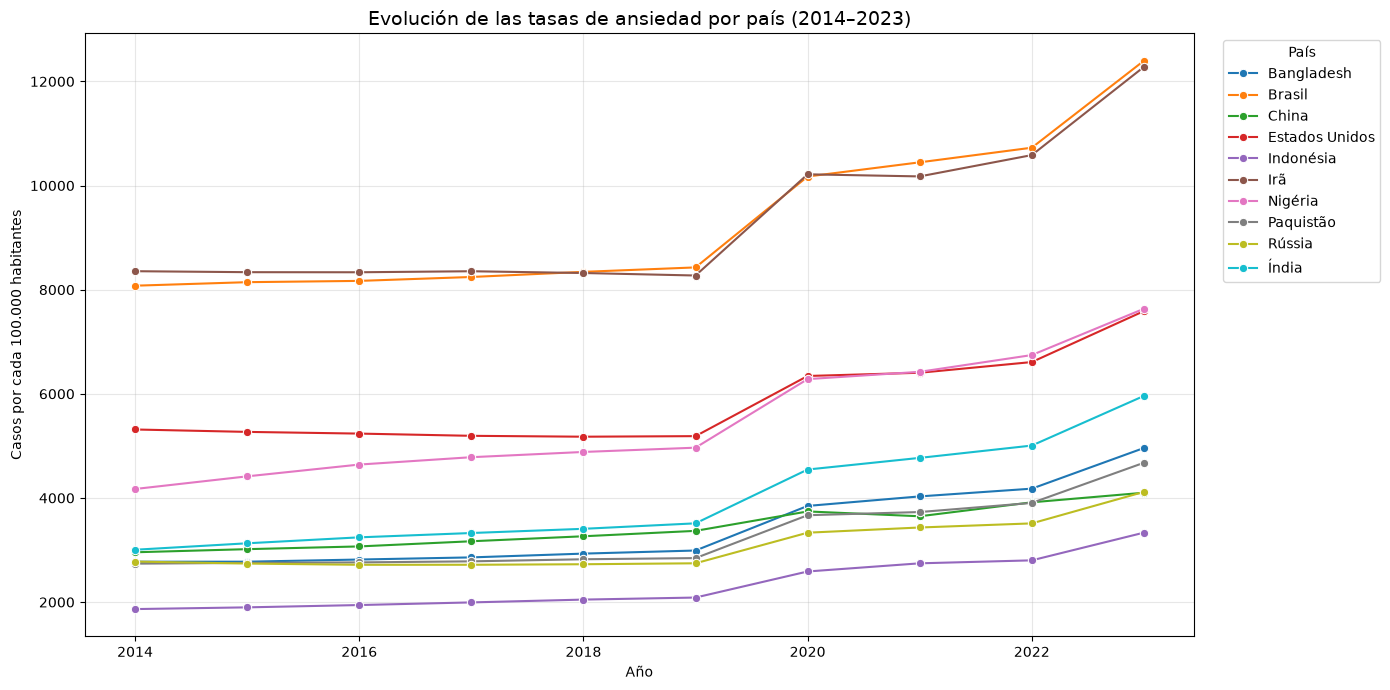

In [271]:
# La primera etapa consistirá en comprender cómo evolucionan la ansiedad y la depresión a lo largo de dos décadas.
# Comencemos con tres preguntas: 1. ¿Cómo han evolucionado las tasas de ansiedad en diferentes países? 2. ¿Cómo evolucionan las tasas de depresión? 3. ¿Qué países presentarán las tasas más elevadas en 2023?


# Análisis exploratorio: evolución de la ansiedad

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_final,
    x="year",
    y="anxiety_rate_per_100k",
    hue="country",
    marker="o"
)

plt.title(
    "Evolución de las tasas de ansiedad por país (2014–2023)",
    fontsize=14
)
plt.xlabel("Año")
plt.ylabel("Casos por cada 100.000 habitantes")
plt.legend(title="País", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


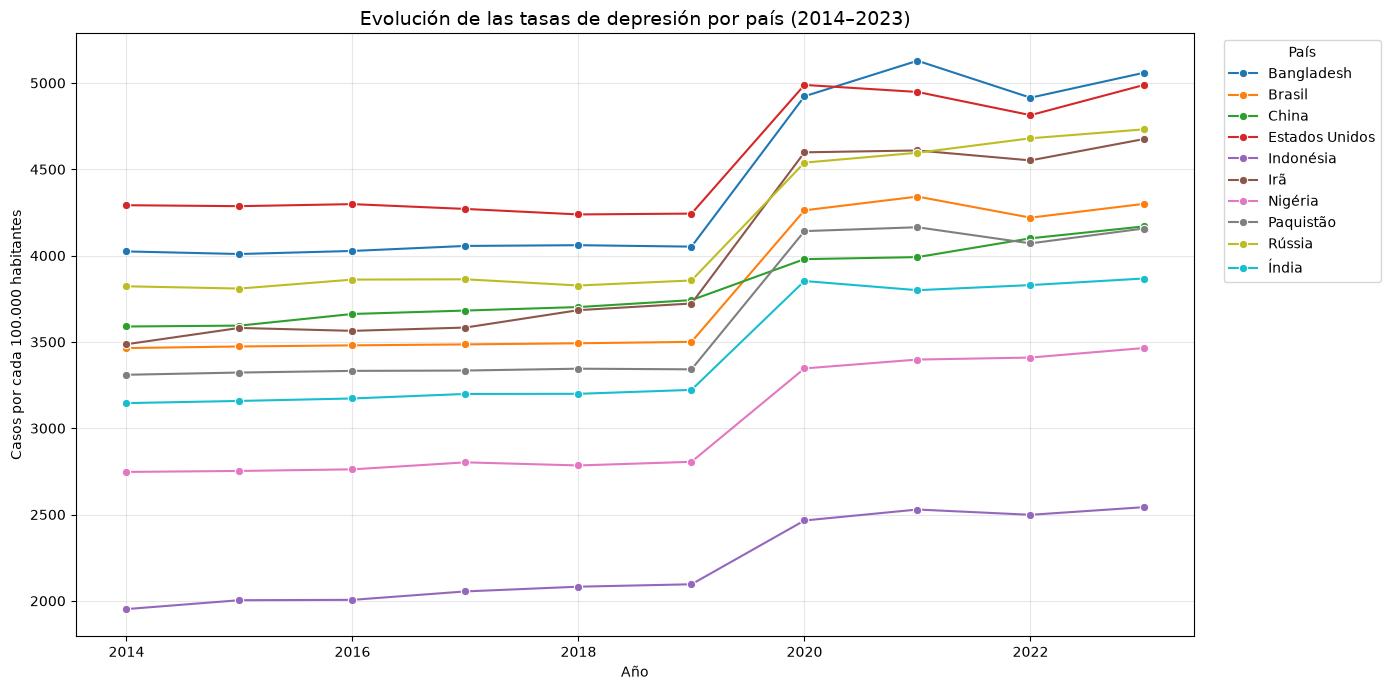

In [272]:
# Análisis exploratorio: evolución de la depresión

plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_final,
    x="year",
    y="depression_rate_per_100k",
    hue="country",
    marker="o"
)

plt.title(
    "Evolución de las tasas de depresión por país (2014–2023)",
    fontsize=14
)
plt.xlabel("Año")
plt.ylabel("Casos por cada 100.000 habitantes")
plt.legend(title="País", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


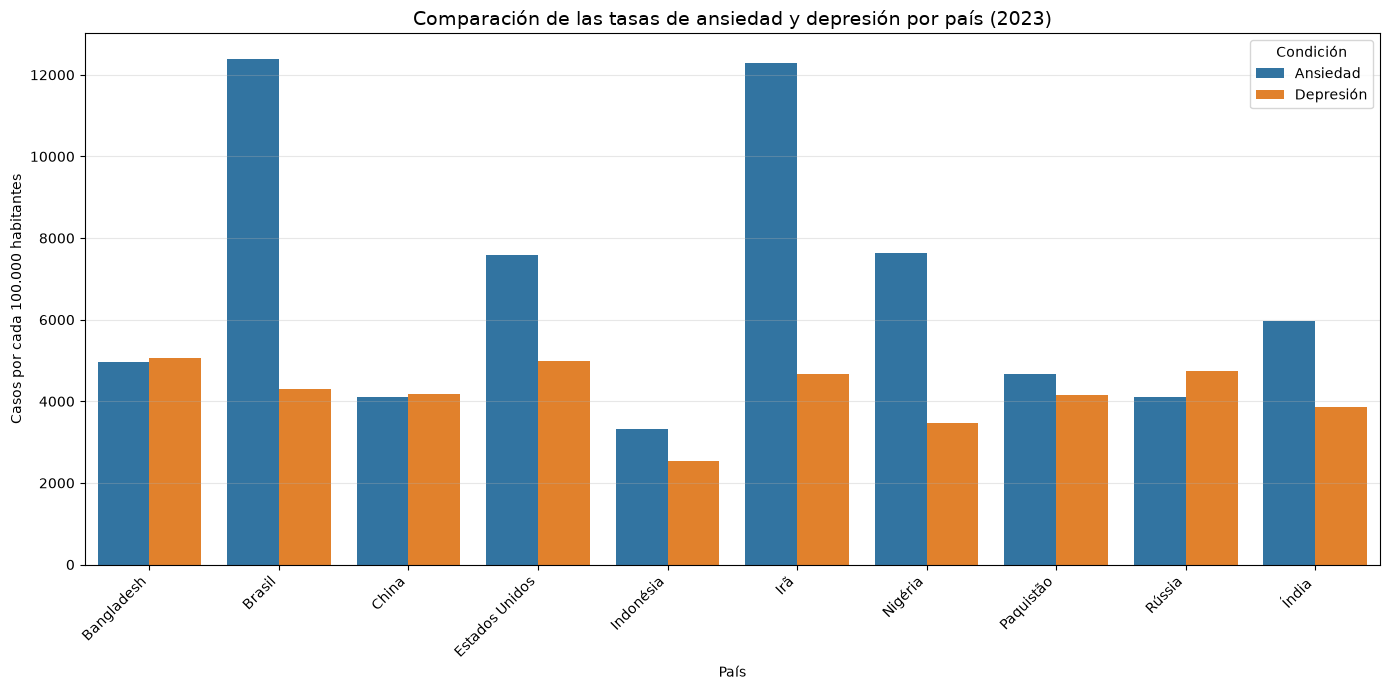

In [273]:
# Comparación de las tasas de ansiedad y depresión por país (2023)

df_2023 = df_final[df_final["year"] == 2023].copy()

df_comparacion = df_2023.melt(
    id_vars="country",
    value_vars=[
        "anxiety_rate_per_100k",
        "depression_rate_per_100k"
    ],
    var_name="condition",
    value_name="rate"
)

df_comparacion["condition"] = df_comparacion["condition"].map({
    "anxiety_rate_per_100k": "Ansiedad",
    "depression_rate_per_100k": "Depresión"
})

plt.figure(figsize=(14, 7))

sns.barplot(
    data=df_comparacion,
    x="country",
    y="rate",
    hue="condition"
)

plt.title(
    "Comparación de las tasas de ansiedad y depresión por país (2023)",
    fontsize=14
)
plt.xlabel("País")
plt.ylabel("Casos por cada 100.000 habitantes")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Condición")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

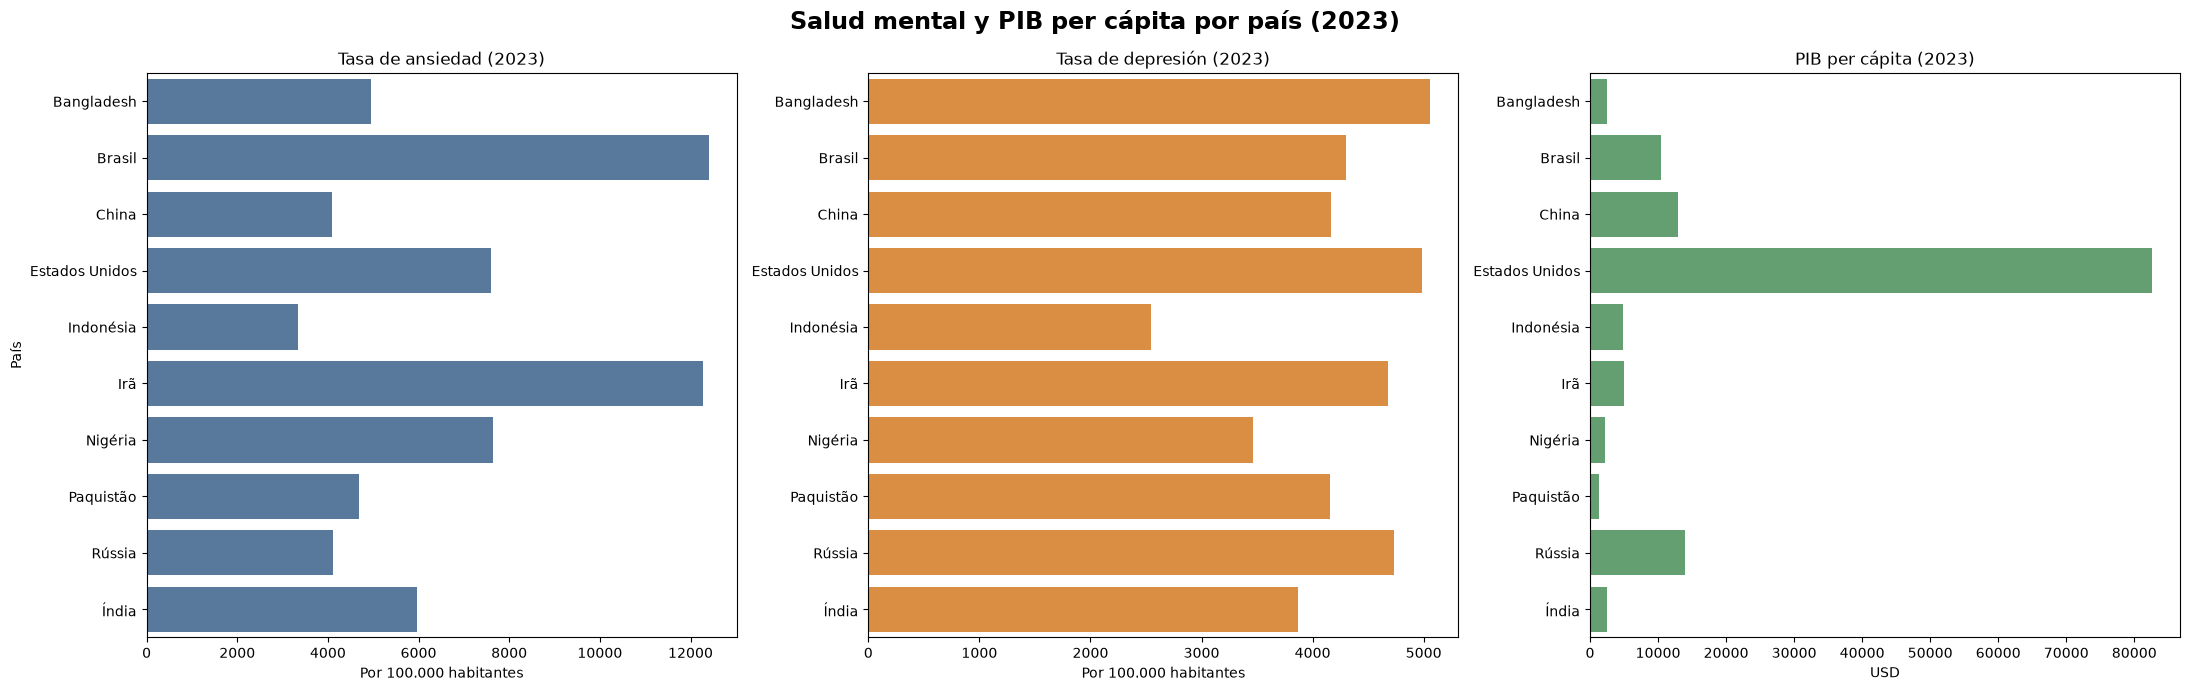

In [274]:
# Filtrar somente o ano de 2023
df_2023 = df_final[df_final["year"] == 2023].copy()

# Organizar os países em ordem alfabética
df_2023 = df_2023.sort_values("country", ascending=True)

# Definir uma cor para cada indicador
cores = {
    "ansiedad": "#4C78A8",   # Azul
    "depresion": "#F28E2B",  # Naranja
    "pib": "#59A96A"         # Verde
}

# Criar figura com três gráficos
fig, axes = plt.subplots(1, 3, figsize=(22, 7))

# 1. Taxa de ansiedade
sns.barplot(
    data=df_2023,
    x="anxiety_rate_per_100k",
    y="country",
    color=cores["ansiedad"],
    ax=axes[0]
)

axes[0].set_title("Tasa de ansiedad (2023)")
axes[0].set_xlabel("Por 100.000 habitantes")
axes[0].set_ylabel("País")

# 2. Taxa de depressão
sns.barplot(
    data=df_2023,
    x="depression_rate_per_100k",
    y="country",
    color=cores["depresion"],
    ax=axes[1]
)

axes[1].set_title("Tasa de depresión (2023)")
axes[1].set_xlabel("Por 100.000 habitantes")
axes[1].set_ylabel("")

# 3. PIB per capita
sns.barplot(
    data=df_2023,
    x="gdp_per_capita",
    y="country",
    color=cores["pib"],
    ax=axes[2]
)

axes[2].set_title("PIB per cápita (2023)")
axes[2].set_xlabel("USD")
axes[2].set_ylabel("")

# Título geral
fig.suptitle(
    "Salud mental y PIB per cápita por país (2023)",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## 6. Relación entre salud mental y PIB per cápita

En esta sección exploramos la posible relación entre el PIB per cápita y las tasas de ansiedad y depresión en los diez países seleccionados durante el período 2014–2023.

El objetivo es identificar posibles patrones y asociaciones entre las variables económicas y los indicadores de salud mental.

Para ello, utilizaremos gráficos de dispersión y el coeficiente de correlación de Pearson.

Es importante destacar que una correlación no implica causalidad. Además, el PIB per cápita está expresado en USD corrientes, por lo que no se ajusta por inflación.

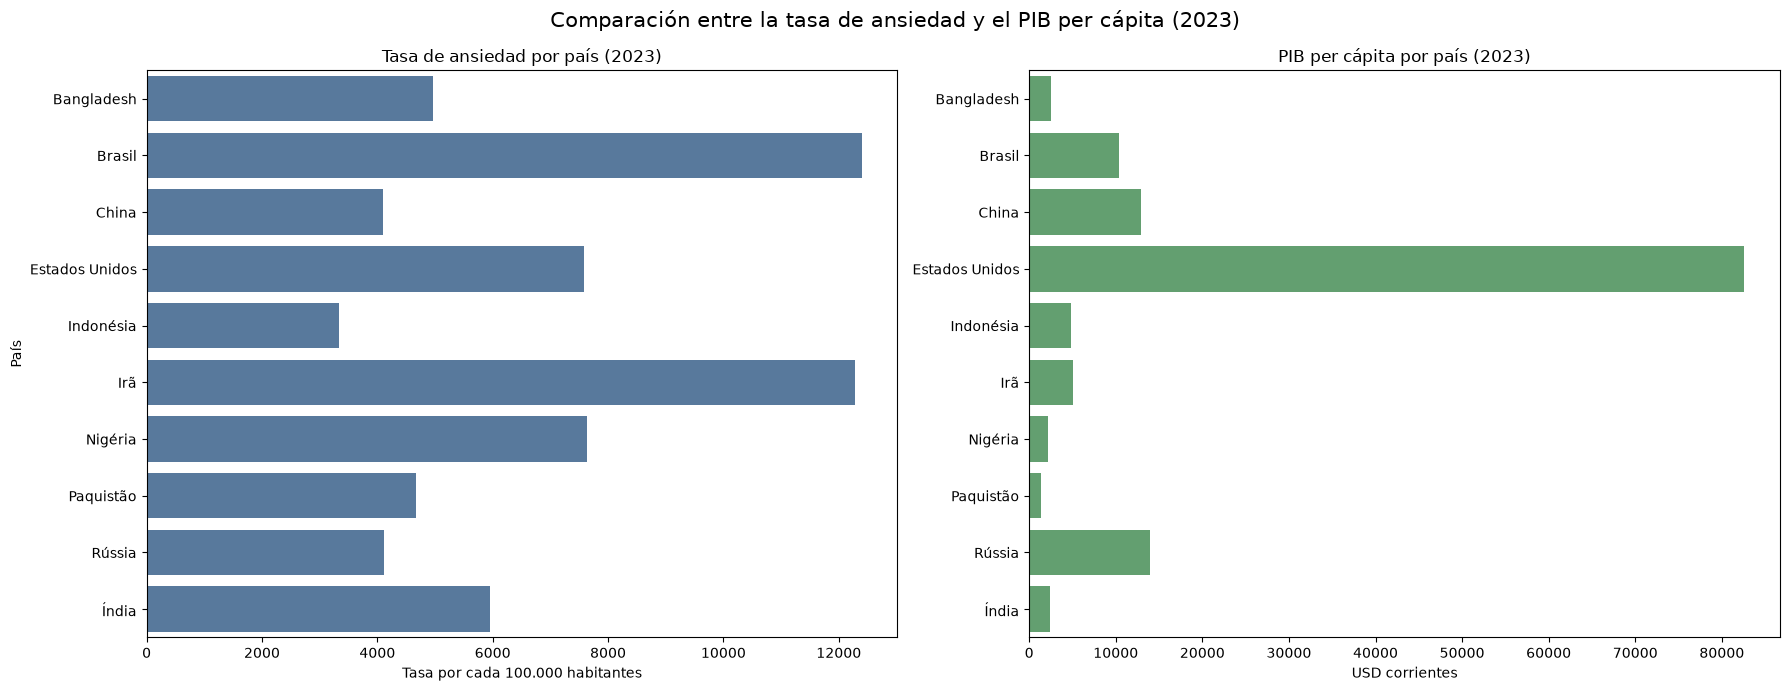

In [281]:
# Comparación del PIB per cápita y la tasa de ansiedad por país (2023)

df_2023 = (
    df_final[df_final["year"] == 2023]
    .copy()
    .sort_values("country")
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Gráfico de barras: tasa de ansiedad
sns.barplot(
    data=df_2023,
    x="anxiety_rate_per_100k",
    y="country",
    color="#4C78A8",
    ax=axes[0]
)

axes[0].set_title("Tasa de ansiedad por país (2023)")
axes[0].set_xlabel("Tasa por cada 100.000 habitantes")
axes[0].set_ylabel("País")

# Gráfico de barras: PIB per cápita
sns.barplot(
    data=df_2023,
    x="gdp_per_capita",
    y="country",
    color="#59A96A",
    ax=axes[1]
)

axes[1].set_title("PIB per cápita por país (2023)")
axes[1].set_xlabel("USD corrientes")
axes[1].set_ylabel("")

fig.suptitle(
    "Comparación entre la tasa de ansiedad y el PIB per cápita (2023)",
    fontsize=15
)

plt.tight_layout()
plt.show()

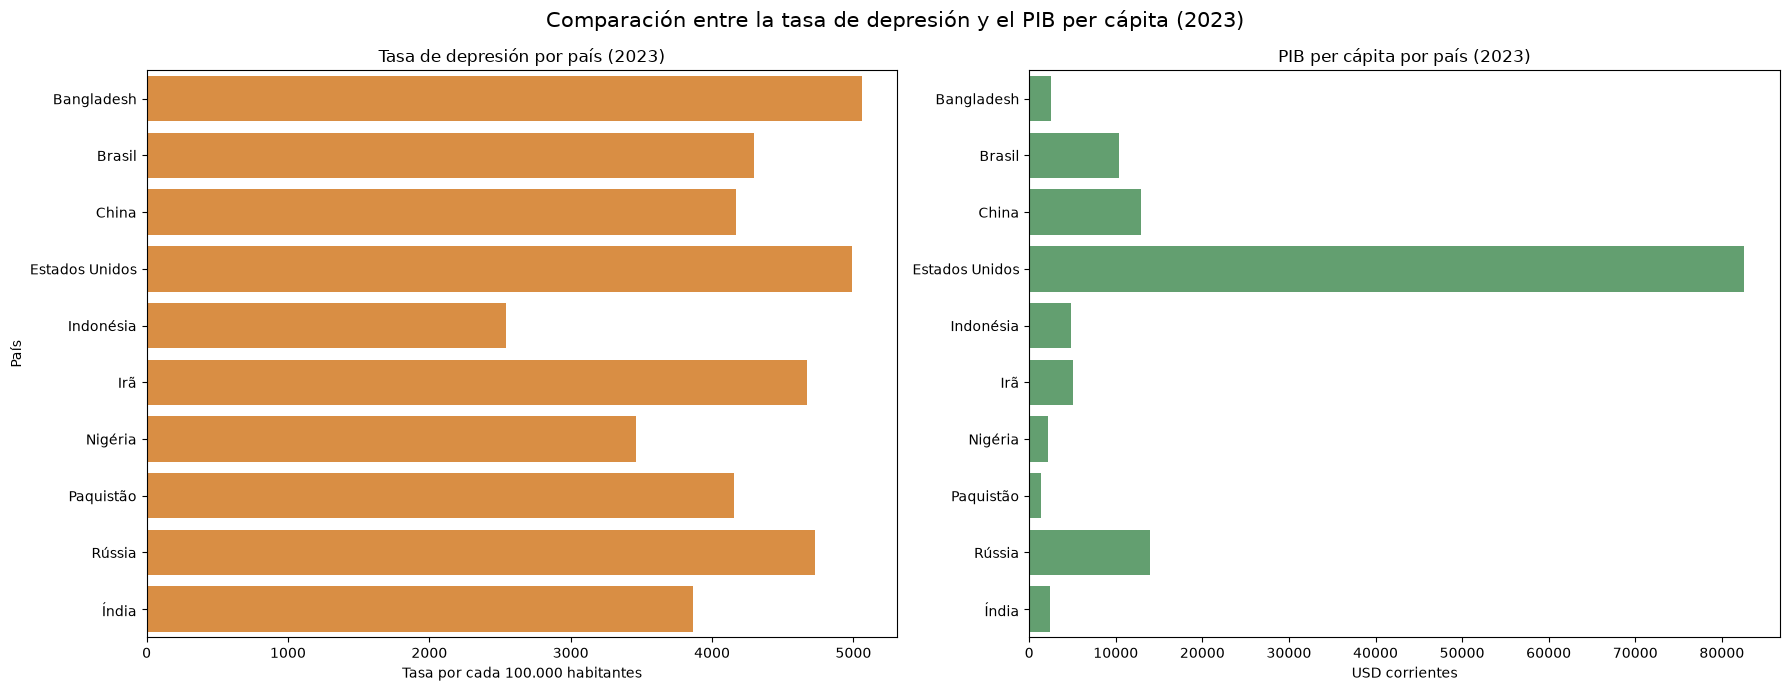

In [282]:
# Comparación del PIB per cápita y la tasa de depresión por país (2023)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Gráfico de barras: tasa de depresión
sns.barplot(
    data=df_2023,
    x="depression_rate_per_100k",
    y="country",
    color="#F28E2B",
    ax=axes[0]
)

axes[0].set_title("Tasa de depresión por país (2023)")
axes[0].set_xlabel("Tasa por cada 100.000 habitantes")
axes[0].set_ylabel("País")

# Gráfico de barras: PIB per cápita
sns.barplot(
    data=df_2023,
    x="gdp_per_capita",
    y="country",
    color="#59A96A",
    ax=axes[1]
)

axes[1].set_title("PIB per cápita por país (2023)")
axes[1].set_xlabel("USD corrientes")
axes[1].set_ylabel("")

fig.suptitle(
    "Comparación entre la tasa de depresión y el PIB per cápita (2023)",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [277]:
# Calcular la correlación de Pearson

correlacion_ansiedad = df_final[
    ["gdp_per_capita", "anxiety_rate_per_100k"]
].corr(method="pearson").iloc[0, 1]

correlacion_depresion = df_final[
    ["gdp_per_capita", "depression_rate_per_100k"]
].corr(method="pearson").iloc[0, 1]

print("Correlación entre el PIB per cápita y la tasa de ansiedad:")
print(round(correlacion_ansiedad, 3))

print("\nCorrelación entre el PIB per cápita y la tasa de depresión:")
print(round(correlacion_depresion, 3))

Correlación entre el PIB per cápita y la tasa de ansiedad:
0.154

Correlación entre el PIB per cápita y la tasa de depresión:
0.423


In [278]:
# Resumen de las correlaciones

resumen_correlaciones = pd.DataFrame({
    "Relacion": [
        "PIB per cápita y ansiedad",
        "PIB per cápita y depresión"
    ],
    "Correlacion_Pearson": [
        correlacion_ansiedad,
        correlacion_depresion
    ]
})

display(resumen_correlaciones)

,Relacion,Correlacion_Pearson
0,PIB per cápita y ansiedad,0.153594
1,PIB per cápita y depresión,0.423465


"En esta parte del proyecto queremos analizar si existe alguna relación entre el PIB per cápita y las tasas de ansiedad y depresión.

Para ello, comparamos los indicadores económicos con las tasas de salud mental de los diez países seleccionados.

Utilizamos gráficos de barras para comparar los países y el coeficiente de correlación de Pearson para observar si existe una relación positiva, negativa o si no hay una relación lineal clara.

Es importante destacar que una correlación no significa causalidad. Es decir, aunque encontremos una relación entre el PIB y la salud mental, no podemos afirmar que uno sea la causa del otro.

Nuestro objetivo es identificar patrones y comprender mejor las diferencias entre los países."

## 7. Exportar el dataframe limpio

In [279]:
# Exportar el dataframe limpio

from pathlib import Path

# Crear la carpeta de resultados si no existe
CARPETA_RESULTADOS = Path("resultados")
CARPETA_RESULTADOS.mkdir(exist_ok=True)

# Definir la ruta del archivo
RUTA_CSV = CARPETA_RESULTADOS / "ray_of_hope_dataframe_limpio.csv"

# Exportar el dataframe
df_final.to_csv(
    RUTA_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado correctamente:")
print(RUTA_CSV)

Archivo exportado correctamente:
resultados\ray_of_hope_dataframe_limpio.csv


In [280]:
# Verificar el archivo exportado

df_verificacion = pd.read_csv(RUTA_CSV)

print("Dimensiones del archivo exportado:")
print(df_verificacion.shape)

print("\nPrimeras filas:")
display(df_verificacion.head())

print("\nValores nulos:")
print(df_verificacion.isnull().sum().sum())

Dimensiones del archivo exportado:
(100, 10)

Primeras filas:


,country,iso3,year,anxiety_rate_per_100k,depression_rate_per_100k,anxiety_cases,depression_cases,gdp_per_capita,population,income_group
0,Bangladesh,BGD,2014,2775.790760,4024.279935,4.189761e+06,6.074223e+06,1094.461997,157964929.0,Lower middle income
1,Bangladesh,BGD,2015,2776.364118,4009.240489,4.253739e+06,6.142661e+06,1224.386477,159383179.0,Lower middle income
2,Bangladesh,BGD,2016,2817.893146,4027.015866,4.384460e+06,6.265777e+06,1649.283809,160811932.0,Lower middle income
3,Bangladesh,BGD,2017,2858.994055,4056.071821,4.519482e+06,6.411816e+06,1811.082217,162186147.0,Lower middle income
4,Bangladesh,BGD,2018,2931.516578,4060.337299,4.709527e+06,6.522995e+06,1965.243727,163523103.0,Lower middle income



Valores nulos:
0


### Resultado de la exportación

El dataframe final se ha exportado en formato CSV para facilitar su reutilización en futuras consultas, visualizaciones y análisis.

El archivo contiene los datos de los diez países seleccionados, para el período 2014–2023, integrando los indicadores de salud mental con el PIB per cápita, la población y el grupo de ingresos.

La exportación conserva los nombres de las columnas y no incluye el índice del dataframe.

## Notas metodológicas

- La tasa de prevalencia ajustada por edad se usa para comparar; no equivale a la tasa cruda de la población.
- La métrica Number del GBD ofrece una estimación de casos para cada país y año. Es una estimación modelada, no un conteo de personas diagnosticadas.
- El PIB per cápita está expresado en USD corrientes y se muestra como contexto, no como medida directa de vulnerabilidad individual.
- El grupo de ingresos es la clasificación actual publicada por el Banco Mundial; no es una serie histórica anual.
- El top 10 exige 8 años disponibles como mínimo para cada trastorno. Comparen la cobertura antes de interpretar diferencias.
- No se incluyen agregados regionales en la lista de países.
